<!-- This is a template that you should use to generate your lab reports for AE801 course work-->
# **Lab Report: Implementing the Leapfrog Method to solve an IVP**
Name: Aathi Skantha Roopan T  

Register Number: SC26M001  

Course: AE801 — Scientific Computing Lab I 

# Required packages

In [4]:
# do not change line below


# import required packages here
import numpy as np
import matplotlib.pyplot as plt

# Problem statement

To implement the leapfrog numerical integration method for solving an initial value problem and study its accuracy, convergence, and stability.

# Approach and numerical method

The given differential equations are

$$dx/dt=v$$

 $$ dv/dt = -(w_p)^2 / x $$

where the normalized plasma frequency is $w_p = 1$

Therefore 

$$dx/dt = v$$
$$dv/dt = -x$$

The initial conditions are $x(0)=0.5$ , $v(0)=0$

**Leapfrog update equations**

The Leapfrog method stores position and velocity at different time levels:
- Position $x_n$ is stored at time $t_n=nh$
- Velocity $v_{n+ 1/2}$ is stored at time $t_{n+1/2}=(n+\frac12)h$
- The velocity update, called the kick, is
$$v_{n+1/2}=v_{n-1/2}-h x_n $$
- The position update, called the drift, is
$${x_{n+1}=x_n+h v_{n+1/2}}$$
Here, $h$ is the time step.

Because the given initial velocity is specified at $t=0$, we must first calculate the velocity at $(t=-h/2)$

# Leapfrog Function

In [5]:
wp = 1.0

In [6]:
def leapfrog(x, v, h):
    v_new = v - h * wp**2 * x
    x_new = x + h * v_new
    return x_new, v_new

- x : Position at the current whole time level
- v : Velocity at the previous half time level
- h : Time step

$$v_{new}=v+h(a(x))$$
The acceleration is
$a(x)=-w_p^2x$
So
$${v_{{new}}=v-h\omega_p^2x}$$

$${x_{{new}}=x+h v_{{new}}}$$

**Initial Half step velocity**

The initial conditions give
$x_0=0.5$ , $v_0=0$
However, the Leapfrog method requires the starting velocity \(v_{-1/2}\), which is located half a time step before $t=0$

The assignment specifies
$$v_{-1/2}=v_0-\frac{h}{2}a(x_0)$$
Since
$$a(x_0)=-\omega_p^2x_0$$
substituting gives
$$v_{-1/2}=v_0-{h}(-\omega_p^2x_0)/2$$
Therefore,
$${v_{-1/2}=v_0+\frac{h}{2}\omega_p^2x_0}$$

For $$(w_p=1)$$ $$v_0=0$$ $$x_0=0.5$$
It is
$${v_{-1/2}=0.25h}$$
For the specified time step $h=0.1$,

$$v_{-1/2}=0.25(0.1)$$

Hence,

$${v_{-1/2}=0.025}$$

In [7]:
h = 0.1
wp = 1
x0 = 0.5
v0 = 0.0

v_half = v0 + 0.5 * h * wp**2 * x0

print("Initial position =", x0)
print("Initial half-step velocity =", v_half)

Initial position = 0.5
Initial half-step velocity = 0.025


# Task — Integrate to $t$=20 and Compare with the Exact Solution

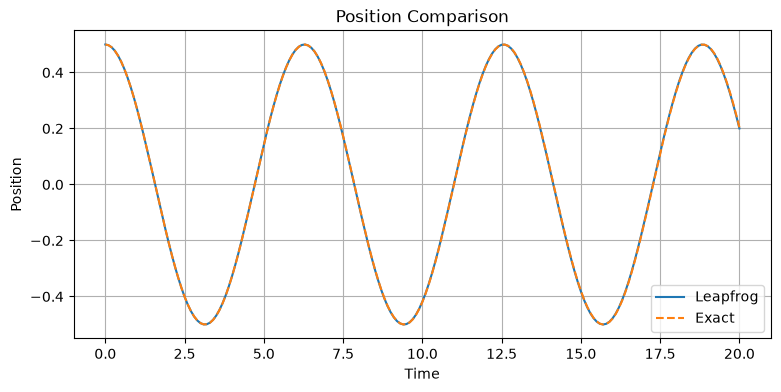

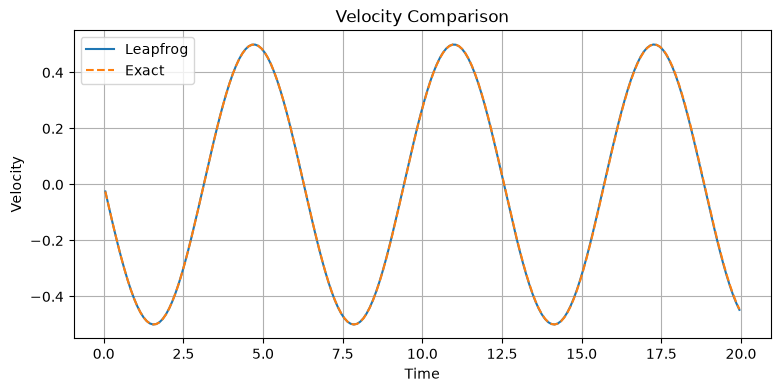

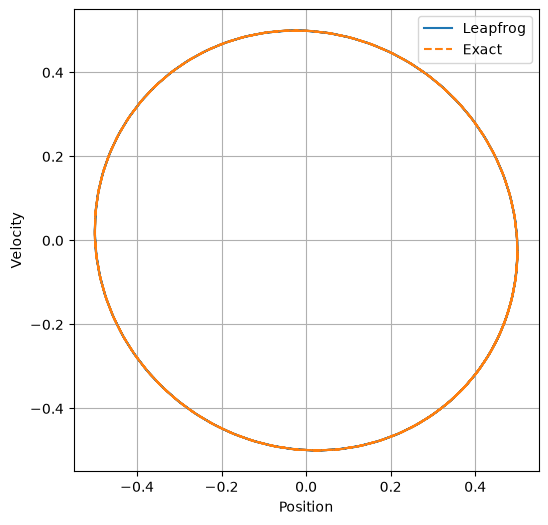

In [22]:
def solve_leapfrog(h, t_end=20.0, staggered=True):
    N = round(t_end / h)

    t = np.arange(N + 1) * h
    tv = t[:-1] + h / 2

    x = np.zeros(N + 1)
    v = np.zeros(N)

    x[0] = 0.5
    v0 = 0.0

    if staggered:
        v_minus = v0 + 0.5 * h * wp**2 * x[0]
    else:
        v_minus = v0

    for n in range(N):
        # Kick: update velocity to the next half-step
        v[n] = v_minus - h * wp**2 * x[n]

        # Drift: update position to the next whole step
        x[n + 1] = x[n] + h * v[n]

        # Carry the updated velocity into the next step
        v_minus = v[n]

    return t, tv, x, v
h = 0.1

t, tv, x, v = solve_leapfrog(h)

x_exact = 0.5 * np.cos(wp * t)
v_exact = -0.5 * np.sin(wp * tv)

plt.figure(figsize=(9, 4))
plt.plot(t, x, label="Leapfrog")
plt.plot(t, x_exact, "--", label="Exact")
plt.xlabel("Time")
plt.ylabel("Position")
plt.title("Position Comparison")
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(9, 4))
plt.plot(tv, v, label="Leapfrog")
plt.plot(tv, v_exact, "--", label="Exact")
plt.xlabel("Time")
plt.ylabel("Velocity")
plt.title("Velocity Comparison")
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(6, 6))
plt.plot(x[:-1], v, label="Leapfrog")
plt.plot(x_exact[:-1], v_exact, "--", label="Exact")
plt.xlabel("Position")
plt.ylabel("Velocity")
plt.legend()
plt.grid()
plt.show()

# Task - Convergence study

Repeat the simulation for $h$= 0.2, 0.1, 0.05, 0.025 and calculate the maximum position error.

The purpose is to determine how the error changes when the time step is reduced.

We first define a solver that returns the numerical position and velocity at their correct time levels.

The argument staggered=True uses the correct half-step initialization. Setting staggered=False uses the assignment's alternative initialization,

$v_{-1/2}=v_0$

**Calculate the maximum position error**

At each whole time level, the exact position is
$$x_{\text{exact}}(t_n)=0.5\cos(t_n)$$
The absolute error is
$$e_n=|x_n-x_{\text{exact}}(t_n)|$$
The maximum error over the complete simulation is
$${E(h)= \max|x_n-x_{\text{exact}}(t_n)|}$$
The observed order of convergence is
$${p=\log_2({E(h)}/{E(h/2)})}$$
For a second-order method, halving the time step should approximately reduce the error by a factor of four:
$$E(h/2)\approx\frac{E(h)}{4}$$
Consequently,
$$p\approx\log_2(4)=2$$

In [21]:
steps = [0.2, 0.1, 0.05, 0.025]

for staggered in [True, False]:
    errors = []

    for h in steps:
        t, tv, x, v = solve_leapfrog(
            h, staggered=staggered
        )

        exact = 0.5 * np.cos(wp * t)
        errors.append(np.max(np.abs(x - exact)))

    print("\nStaggered initialization:", staggered)
    print("h          Maximum error       Order")

    for i, h in enumerate(steps):
        if i == 0:
            print(f"{h:<10} {errors[i]:.8e}       ---")
        else:
            p = np.log2(errors[i - 1] / errors[i])
            print(f"{h:<10} {errors[i]:.8e}       {p:.4f}")


Staggered initialization: True
h          Maximum error       Order
0.2        1.53961535e-02       ---
0.1        3.81528087e-03       2.0127
0.05       9.51694558e-04       2.0032
0.025      2.37790545e-04       2.0008

Staggered initialization: False
h          Maximum error       Order
0.2        6.45570937e-02       ---
0.1        2.86282800e-02       1.1731
0.05       1.34016627e-02       1.0950
0.025      6.47540341e-03       1.0494


# Task - Order of Accuracy

We need to eliminate velocity from the Leapfrog equations.

The velocity update is
$$v_{n+1/2}=v_{n-1/2}-h\omega_p^2x_n$$

The position update is
$$x_{n+1}=x_n+h v_{n+1/2}$$
Rearranging equation (2),
$$v_{n+1/2}={x_{n+1}-x_n}/{h}$$

Similarly, the preceding position update is
$$x_n=x_{n-1}+h v_{n-1/2}$$

Therefore,
$$v_{n-1/2}=(x_n-x_{n-1})/{h}$$

Substitute equations (3) and (4) into equation (1):
$${x_{n+1}-x_n}/{h}={x_n-x_{n-1}}/{h} - (h)w_p^2x_n $$

Multiplying throughout by h
$$x_{n+1}-x_n = x_n-x_{n-1}-h^2\omega_p^2x_n$$

Collecting the position terms
$$x_{n+1}-2x_n+x_{n-1}=-h^2\omega_p^2x_n$$

Hence, the required **central-difference formula** is
$${x_{n+1}-2x_n+x_{n-1}=-\omega_p^2h^2x_n}$$
Equivalently,
$${x_{n+1}=(2-\omega_p^2h^2)x_n-x_{n-1}}$$


**Determining order of accuracy**

Using Taylor expansions about t_n
$$x_{n+1}=x_n+hx'_n+{h^2}{2}x''_n
+{h^3}/{6}x'''_n+{h^4}/{24}x''''_n+....$$
and
$$x_{n-1}=x_n-hx'_n+\frac{h^2}{2}x''_n
-{h^3}/{6}x'''_n+\frac{h^4}{24}x''''_n+....$$

Adding these expressions and subtracting 2x_n,

$$x_{n+1}-2x_n+x_{n-1} = h^2x''_n+{h^4}/{12}x''''_n+...$$
Dividing by h^2,
$$
\frac{x_{n+1}-2x_n+x_{n-1}}{h^2}
=x''_n+O(h^2).
$$

Thus, the central-difference approximation to the second derivative has a truncation error of order $h^2.$

Since the equation of motion is
$x''=-\omega_p^2x$ , the Leapfrog method is second-order accurate in time, provided the starting values are initialized consistently.
$$
\boxed{\text{Order of accuracy}=2}
$$

# Results and discussion

# Summary and conculsions

# References